<a href="https://www.kaggle.com/code/ferntanyl/klasifikasi-sampah?scriptVersionId=362194039" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Klasifikasi Gambar Sampah dengan ConvNeXt-Tiny
### Kompetisi Klasifikasi Sampah - Studio Proyek 2 (IF25-40401)

Notebook ini melatih ConvNeXt-Tiny (transfer learning dari ImageNet) untuk mengklasifikasikan foto sampah ke dalam 5 kelas, dan **menghasilkan folder `submission/`** sesuai kontrak tugas:

```
submission/
├── model.py    # get_model() dan get_transform()
└── model.pth   # state_dict model terbaik
```

## Dataset
- Folder `train/` berisi 5 kelas (urutan alfabetis, sama dengan `ImageFolder`): `botol_plastik`, `gelas_plastik`, `kertas_kardus`, `saset_kemasan`, `styrofoam`
- Label diambil dari **nama folder**. `train_sources.csv` hanya mencatat sumber gambar, bukan label.
- Validation set resmi disimpan tim pengajar, jadi kita memotong **`my_val/`** (20%, stratified) dari train untuk validasi lokal, dalam format ImageFolder agar bisa diuji dengan `evaluate.py`.
- Dataset (termasuk `my_val/`) **tidak boleh diunggah** ke repo publik, Kaggle, atau Hugging Face. Cukup unggah kode dan bobot model.

## Metrik
Penilaian memakai **Macro-F1**, jadi pemilihan model terbaik di notebook ini juga berdasarkan Macro-F1 (bukan akurasi).

## Environment
venv (python 3.11.9)

## Anggota kelompok
- Muhammad Nelwan Fakhri (122140173)
- Ali Akbar   (123140162)
- Raditya Erza Farandi   (122140209)

## 1. Import Library

In [1]:
import os
import sys
import time
import random
import shutil
import importlib
import subprocess
from itertools import cycle

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import (Compose, RandomResizedCrop, RandomHorizontalFlip,
                                    RandomRotation, ColorJitter, ToTensor, Normalize)
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, f1_score

# Seed untuk reproduksibilitas
RANDOM_SEED = 2025
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

def check_set_gpu(override=None):
    if override is None:
        if torch.cuda.is_available():
            device = torch.device('cuda')
            print(f"Using GPU: {torch.cuda.get_device_name(0)}")
        elif torch.backends.mps.is_available():
            device = torch.device('mps')
            print("Using MPS")
        else:
            device = torch.device('cpu')
            print("Using CPU")
    else:
        device = torch.device(override)
    return device

device = check_set_gpu()

Using GPU: Tesla T4


## 2. Lokasi Dataset dan Daftar Gambar

Label diambil dari nama subfolder di `train/` (gaya `ImageFolder`). Urutan kelas **harus** alfabetis:
`0 botol_plastik · 1 gelas_plastik · 2 kertas_kardus · 3 saset_kemasan · 4 styrofoam`.

Sel di bawah mencari folder `train/` otomatis (path Kaggle Anda sudah dimasukkan). Jika gagal, isi `TRAIN_DIR` secara manual.

In [2]:

TRAIN_DIR = None

EXPECTED_CLASSES = [
    'botol_plastik',
    'gelas_plastik',
    'kertas_kardus',
    'saset_kemasan',
    'styrofoam'
]

IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')


def is_class_root(path):
    """Pastikan folder train berisi semua kelas yang diperlukan."""
    if not os.path.isdir(path):
        return False

    subdirs = {
        d for d in os.listdir(path)
        if os.path.isdir(os.path.join(path, d))
    }

    return set(EXPECTED_CLASSES).issubset(subdirs)


def find_train_dir():
    # Deteksi otomatis berdasarkan environment.
    roots = [
        os.getcwd(),
        os.path.dirname(os.getcwd()),
        '/kaggle/input',
        '/content',
    ]

    visited = set()

    for root in roots:
        if not os.path.isdir(root):
            continue

        root = os.path.abspath(root)

        if root in visited:
            continue
        visited.add(root)

        for dirpath, dirnames, _ in os.walk(root):
            # Lewati direktori yang tidak relevan.
            dirnames[:] = [
                d for d in dirnames
                if d not in {
                    '.git', '.venv', 'venv',
                    'node_modules', '__pycache__',
                    '.ipynb_checkpoints'
                }
            ]

            if (
                os.path.basename(dirpath).lower() == 'train'
                and is_class_root(dirpath)
            ):
                return os.path.abspath(dirpath)

    return None


TRAIN_DIR = find_train_dir()

if TRAIN_DIR is None:
    raise FileNotFoundError(
        "Dataset train tidak ditemukan. "
        "Pastikan folder train berisi kelima folder kelas "
        "dan berada di direktori project atau mount cloud."
    )

print("TRAIN_DIR:", TRAIN_DIR)


def scan_imagefolder(root, class_names):
    # Mengembalikan list (image_path, label_idx).
    out = []

    for idx, cls in enumerate(class_names):
        class_dir = os.path.join(root, cls)

        for dp, _, fs in os.walk(class_dir):
            for f in sorted(fs):
                if f.lower().endswith(IMG_EXT):
                    out.append((os.path.join(dp, f), idx))

    return out


# Pertahankan urutan label yang konsisten.
class_names = EXPECTED_CLASSES.copy()

num_classes = len(class_names)
label_to_idx = {c: i for i, c in enumerate(class_names)}
idx_to_label = {i: c for c, i in label_to_idx.items()}

samples = scan_imagefolder(TRAIN_DIR, class_names)

if not samples:
    raise RuntimeError(
        f"Tidak ada gambar yang ditemukan di {TRAIN_DIR}"
    )

print(f"\nTotal gambar: {len(samples)}")

for i, c in enumerate(class_names):
    count = sum(1 for _, label in samples if label == i)
    print(f"  {i} {c:15s}: {count}")

os.makedirs('submission', exist_ok=True)

TRAIN_DIR: /kaggle/input/datasets/ferntanyl/dataset-mahasiswa/dataset_mahasiswa/train

Total gambar: 2753
  0 botol_plastik  : 523
  1 gelas_plastik  : 521
  2 kertas_kardus  : 365
  3 saset_kemasan  : 673
  4 styrofoam      : 671


## 3. Membuat `my_val/` dan `my_test/`

Dataset dibagi secara stratified menjadi **70% training / 15% validasi / 15% testing**. Data validasi disalin ke `my_val/` untuk pemilihan model selama pelatihan, sedangkan data testing disimpan terpisah di `my_test/` dan hanya digunakan untuk evaluasi akhir.

Folder `my_val/` tetap dapat diuji dengan `evaluate.py`. Jangan commit `my_val/`, `my_test/`, atau dataset ke repo publik karena berisi gambar dataset. Pembagian bersifat deterministik (seed tetap), jadi aman dijalankan ulang.

In [3]:
MY_VAL_DIR = 'my_val'
MY_TEST_DIR = 'my_test'
VAL_RATIO = 0.15
TEST_RATIO = 0.15

all_idx = np.arange(len(samples))
all_labels = [l for _, l in samples]

# Sisihkan 30% data terlebih dahulu untuk validasi + testing.
train_idx, temp_idx = train_test_split(
    all_idx,
    test_size=VAL_RATIO + TEST_RATIO,
    stratify=all_labels,
    random_state=RANDOM_SEED
)

# Bagi sisa 30% menjadi validasi 15% dan testing 15%.
temp_labels = [all_labels[i] for i in temp_idx]
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=TEST_RATIO / (VAL_RATIO + TEST_RATIO),
    stratify=temp_labels,
    random_state=RANDOM_SEED
)

train_samples = [samples[i] for i in train_idx]

def recreate_split_folder(folder, indices):
    # Buat ulang folder split agar tidak tercampur dengan hasil run sebelumnya.
    if os.path.exists(folder):
        shutil.rmtree(folder)
    for c in class_names:
        os.makedirs(os.path.join(folder, c), exist_ok=True)

    for i in indices:
        src, lbl = samples[i]
        dst = os.path.join(folder, class_names[lbl], os.path.basename(src))
        if os.path.exists(dst):
            dst = os.path.join(folder, class_names[lbl], f"{i}_{os.path.basename(src)}")
        shutil.copy2(src, dst)

recreate_split_folder(MY_VAL_DIR, val_idx)
recreate_split_folder(MY_TEST_DIR, test_idx)

# Validasi dan testing dipindai dari folder terpisah.
val_samples = scan_imagefolder(MY_VAL_DIR, class_names)
test_samples = scan_imagefolder(MY_TEST_DIR, class_names)

print(
    f"Train: {len(train_samples)} ({len(train_samples)/len(samples):.1%}) | "
    f"Val: {len(val_samples)} ({len(val_samples)/len(samples):.1%}) | "
    f"Test: {len(test_samples)} ({len(test_samples)/len(samples):.1%})"
)

dist = pd.DataFrame({
    'kelas': class_names,
    'train': [sum(1 for _, l in train_samples if l == i) for i in range(num_classes)],
    'val': [sum(1 for _, l in val_samples if l == i) for i in range(num_classes)],
    'test': [sum(1 for _, l in test_samples if l == i) for i in range(num_classes)],
})
display(dist)

Train: 1927 (70.0%) | Val: 413 (15.0%) | Test: 413 (15.0%)


,kelas,train,val,test
0,botol_plastik,366,78,79
1,gelas_plastik,365,78,78
2,kertas_kardus,255,55,55
3,saset_kemasan,471,101,101
4,styrofoam,470,101,100


## 4. `submission/model.py`

File ini adalah **satu-satunya sumber kebenaran** untuk arsitektur dan transform validasi, sehingga yang dipakai saat latihan identik dengan yang dipakai `evaluate.py`.

- `get_model()` hanya membangun arsitektur (**`weights=None`**, tidak mengunduh bobot, tidak memuat `model.pth`). Parameter `pretrained=True` hanya dipakai di notebook ini untuk latihan; `evaluate.py` memanggil `get_model()` tanpa argumen.
- `get_transform()` menerima `PIL.Image` (RGB) dan mengembalikan tensor `[3, H, W]`.

In [4]:
%%writefile submission/model.py
import torch.nn as nn
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from torchvision.transforms import Compose, Resize, ToTensor, Normalize

# Urutan kelas (alfabetis, sama dengan torchvision ImageFolder):
# 0 botol_plastik . 1 gelas_plastik . 2 kertas_kardus . 3 saset_kemasan . 4 styrofoam
CLASS_NAMES = ["botol_plastik", "gelas_plastik", "kertas_kardus", "saset_kemasan", "styrofoam"]
NUM_CLASSES = 5
IMG_SIZE = 300                       # ukuran input (native ConvNeXt-Tiny 224, tapi fully-convolutional sehingga 300 tetap bisa)
MEAN = [0.485, 0.456, 0.406]         # statistik ImageNet
STD = [0.229, 0.224, 0.225]


def get_model(pretrained=False):
    """Bangun arsitektur saja. Default pretrained=False: TIDAK mengunduh bobot
    dan TIDAK memuat model.pth (bobot dimuat oleh evaluate.py).
    pretrained=True hanya untuk keperluan latihan di notebook."""
    weights = ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if pretrained else None
    model = convnext_tiny(weights=weights)
    model.classifier = nn.Sequential(
        model.classifier[0],         # LayerNorm2d bawaan ConvNeXt
        nn.Flatten(1),
        nn.Dropout(p=0.3),
        nn.Linear(768, 1024),
        nn.ReLU(),
        nn.BatchNorm1d(1024),
        nn.Dropout(p=0.2),
        nn.Linear(1024, NUM_CLASSES),
    )
    return model                     # output: logits [batch, 5]


def get_transform():
    """Transform validasi: PIL.Image (RGB) -> Tensor [3, H, W]."""
    return Compose([
        Resize((IMG_SIZE, IMG_SIZE)),
        ToTensor(),
        Normalize(mean=MEAN, std=STD),
    ])

Writing submission/model.py


In [5]:
# Impor model.py yang baru ditulis (reload agar perubahan terbaru terbaca)
sys.path.insert(0, os.getcwd())
import submission.model as sub_model
importlib.reload(sub_model)

assert sub_model.CLASS_NAMES == class_names, "CLASS_NAMES di model.py tidak sama dengan urutan folder"

eval_transform = sub_model.get_transform()   # dipakai untuk validasi (identik dengan evaluate.py)

# Augmentasi hanya untuk training; bagian akhirnya sama dengan eval_transform
train_transform = Compose([
    RandomResizedCrop(sub_model.IMG_SIZE, scale=(0.6, 1.0)),
    RandomHorizontalFlip(),
    RandomRotation(15),
    ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    ToTensor(),
    Normalize(mean=sub_model.MEAN, std=sub_model.STD),
])
print("model.py berhasil diimpor. Transform validasi:")
print(eval_transform)

model.py berhasil diimpor. Transform validasi:
Compose(
    Resize(size=(300, 300), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 5. Dataset dan DataLoader

Gambar dimuat dengan **PIL** (`Image.open(...).convert('RGB')`), sama seperti yang dilakukan `evaluate.py`, sehingga tidak ada selisih pra-pemrosesan antara latihan dan evaluasi (sebelumnya memakai `cv2`).

In [6]:
class DatasetSampah(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples          # list of (path, label_idx)
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert('RGB')
        return self.transform(image), label, path

# Hyperparameter
num_epochs = 15
batch_size = 32
lr_backbone = 3e-4      # backbone pretrained: learning rate lebih kecil
lr_head = 1e-3          # classifier baru
label_smoothing = 0.1   # membantu menghadapi label noise
USE_CLASS_WEIGHTS = True

train_dataset = DatasetSampah(train_samples, train_transform)
val_dataset   = DatasetSampah(val_samples,   eval_transform)

num_workers = 0 if os.name == 'nt' else 2
pin = (device.type == 'cuda')
# drop_last=True: batch sisa berukuran 1 akan membuat BatchNorm1d error saat training
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                          num_workers=num_workers, pin_memory=pin, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False,
                        num_workers=num_workers, pin_memory=pin)

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)}")
print(f"Kelas: {label_to_idx}")

Train: 1927 | Val: 413
Kelas: {'botol_plastik': 0, 'gelas_plastik': 1, 'kertas_kardus': 2, 'saset_kemasan': 3, 'styrofoam': 4}


In [7]:
class DatasetSampah(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples          # list of (path, label_idx)
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert('RGB')
        return self.transform(image), label, path

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Hyperparameters
num_epochs = 25
min_delta = 1e-3
batch_size = 32

lr_backbone = 1e-4
lr_head = 5e-4

label_smoothing = 0.05
USE_CLASS_WEIGHTS = True

train_dataset = DatasetSampah(train_samples, train_transform)
val_dataset = DatasetSampah(val_samples, eval_transform)
test_dataset = DatasetSampah(test_samples, eval_transform)

num_workers = 0 if os.name == "nt" else 2
pin = device.type == "cuda"

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=pin,
    drop_last=False,
    generator=generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin,
)

print(
    f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | "
    f"Test: {len(test_dataset)}"
)
print(f"Classes: {label_to_idx}")
print(f"Device: {device}")

Train: 1927 | Val: 413 | Test: 413
Classes: {'botol_plastik': 0, 'gelas_plastik': 1, 'kertas_kardus': 2, 'saset_kemasan': 3, 'styrofoam': 4}
Device: cuda


Batch image shape: (32, 3, 300, 300)
Labels (8 pertama): [0, 0, 2, 1, 3, 4, 0, 2] ['botol_plastik', 'botol_plastik', 'kertas_kardus', 'gelas_plastik', 'saset_kemasan', 'styrofoam', 'botol_plastik', 'kertas_kardus']
Range tensor: [-2.118, 2.640]


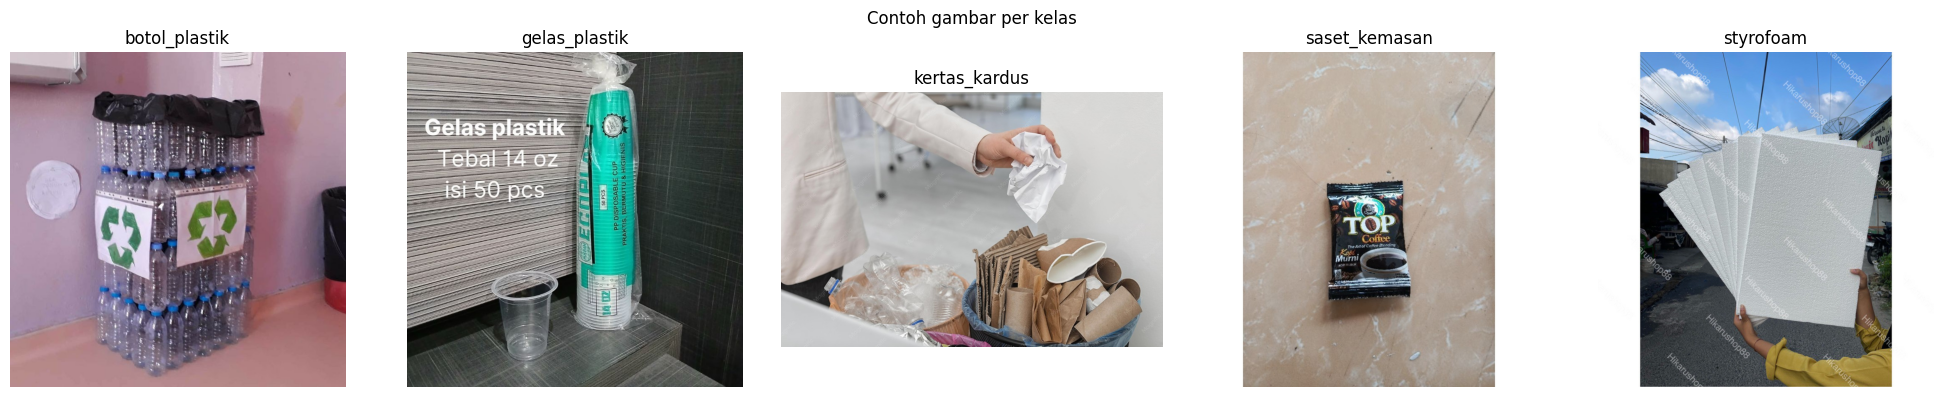

In [8]:
# Debug singkat: pastikan satu batch bisa dimuat
images, labels, paths = next(iter(train_loader))
print("Batch image shape:", tuple(images.shape))
print("Labels (8 pertama):", labels[:8].tolist(), [idx_to_label[int(l)] for l in labels[:8]])
print(f"Range tensor: [{images.min():.3f}, {images.max():.3f}]")

# Contoh gambar tiap kelas
fig, axes = plt.subplots(1, num_classes, figsize=(4*num_classes, 4))
for ax, (i, cls) in zip(axes, enumerate(class_names)):
    p = next(p for p, l in samples if l == i)
    ax.imshow(Image.open(p).convert('RGB'))
    ax.set_title(cls)
    ax.axis('off')
plt.suptitle('Contoh gambar per kelas')
plt.tight_layout()
plt.show()

## 6. Fungsi Pelatihan dan Validasi

`validate` menghitung **Macro-F1** (rata-rata F1 kelima kelas), metrik yang dipakai untuk menilai tugas, selain loss dan akurasi.

In [9]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, ema=None):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    pbar = tqdm(dataloader, desc='Training')
    for batch_idx, (inputs, targets, _) in enumerate(pbar):
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        if ema is not None:
            ema.update_parameters(model)      # <-- new

        total_loss += loss.item()
        correct += outputs.argmax(1).eq(targets).sum().item()
        total += targets.size(0)
        pbar.set_postfix({'loss': total_loss/(batch_idx+1), 'acc': 100.*correct/total})

    return total_loss/len(dataloader), 100.*correct/total

@torch.no_grad()
def validate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_preds, all_targets = [], []

    for inputs, targets, _ in tqdm(dataloader, desc='Validation'):
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        total_loss += criterion(outputs, targets).item()
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

    all_preds, all_targets = np.array(all_preds), np.array(all_targets)
    acc = 100. * (all_preds == all_targets).mean()
    macro_f1 = f1_score(all_targets, all_preds, average='macro')
    return total_loss/len(dataloader), acc, macro_f1

@torch.no_grad()
def predict(model, dataloader, device):
    # Kembalikan preds, labels, probs, paths untuk analisis detail
    model.eval()
    preds, labels, probs, paths = [], [], [], []
    for inputs, targets, p in tqdm(dataloader, desc='Predicting'):
        out = torch.softmax(model(inputs.to(device)), dim=1)
        preds.extend(out.argmax(1).cpu().numpy())
        labels.extend(targets.numpy())
        probs.extend(out.cpu().numpy())
        paths.extend(p)
    return np.array(preds), np.array(labels), np.array(probs), paths

In [10]:
from torch.optim.lr_scheduler import LinearLR, CosineAnnealingLR, SequentialLR
model = sub_model.get_model(pretrained=True).to(device)

# Class weights: square root of inverse frequency, normalized to mean 1
class_weights = None
if USE_CLASS_WEIGHTS:
    counts = np.bincount(
        [l for _, l in train_samples],
        minlength=num_classes
    )
    w = (counts.sum() / (num_classes * counts)) ** 0.5
    w = w / w.mean()

    class_weights = torch.tensor(
        w, dtype=torch.float32
    ).to(device)

    print("Class weights:", {
        class_names[i]: round(float(w[i]), 3)
        for i in range(num_classes)
    })

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=label_smoothing
)


optimizer = torch.optim.AdamW([
    {'params': model.features.parameters(), 'lr': lr_backbone},
    {'params': model.classifier.parameters(), 'lr': lr_head},
], weight_decay=5e-2)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=num_epochs, eta_min=1e-6
)

from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn

ema = AveragedModel(
    model,
    multi_avg_fn=get_ema_multi_avg_fn(0.998),
    use_buffers=True,          # needed: your head has BatchNorm1d
)
SUBMISSION_WEIGHTS = 'submission/model.pth'
RETRAIN = True ## CHANGE THIS PART TO "False" if u wanna use model.pth


history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'val_f1': []
}

best_f1 = -1.0
best_loss = float('inf')
best_epoch = 0
epochs_without_improvement = 0

if os.path.exists(SUBMISSION_WEIGHTS) and not RETRAIN:
    model.load_state_dict(
        torch.load(SUBMISSION_WEIGHTS, map_location=device)
    )

    _, _, best_f1 = validate(
        model, val_loader, criterion, device
    )

    print(
        f"Weights loaded from {SUBMISSION_WEIGHTS}. "
        f"Validation Macro-F1: {best_f1:.4f}"
    )

else:
    for epoch in range(num_epochs):
        lrs = [g['lr'] for g in optimizer.param_groups]

        print(
            f"\nEpoch {epoch + 1}/{num_epochs} "
            f"(lr backbone={lrs[0]:.6f}, head={lrs[1]:.6f})"
        )

        tr_loss, tr_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, device, ema=ema
        )

        va_loss, va_acc, va_f1 = validate(
            ema, val_loader, criterion, device
        )

        # Store metrics for later plotting
        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)
        history['val_f1'].append(va_f1)

        scheduler.step()

        # Improvement means Macro-F1 increases by min_delta.
        # If F1 is effectively tied, lower validation loss wins.
        improved = (
            va_f1 > best_f1 + min_delta
            or (
                abs(va_f1 - best_f1) <= min_delta
                and va_loss < best_loss
            )
        )

        if improved:
            best_f1 = va_f1
            best_loss = va_loss
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        
            # Save best state_dict as CPU tensors
            torch.save(
                {
                    k: v.detach().cpu()
                    for k, v in ema.module.state_dict().items()
                },
                SUBMISSION_WEIGHTS
            )
        
            print(
                f"  -> Best model saved: {SUBMISSION_WEIGHTS} "
                f"(Macro-F1={best_f1:.4f}, "
                f"val_loss={best_loss:.4f})"
            )
        

# No early stopping: continue until num_epochs is reached

    # Restore best checkpoint before final evaluation
    model.load_state_dict(
        torch.load(SUBMISSION_WEIGHTS, map_location=device)
    )

model.eval()

print(
    f"\nBest validation Macro-F1: {best_f1:.4f}"
    + (f" at epoch {best_epoch}" if best_epoch else "")
)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 158MB/s]


Class weights: {'botol_plastik': 1.007, 'gelas_plastik': 1.009, 'kertas_kardus': 1.207, 'saset_kemasan': 0.888, 'styrofoam': 0.889}

Epoch 1/25 (lr backbone=0.000100, head=0.000500)


Validation: 100%|██████████| 13/13 [00:06<00:00,  2.13it/s]


  -> Best model saved: submission/model.pth (Macro-F1=0.7359, val_loss=1.3978)

Epoch 2/25 (lr backbone=0.000100, head=0.000498)


...

  -> Best model saved: submission/model.pth (Macro-F1=0.9668, val_loss=0.3332)

Epoch 24/25 (lr backbone=0.000003, head=0.000009)


Validation: 100%|██████████| 13/13 [00:04<00:00,  3.15it/s]


  -> Best model saved: submission/model.pth (Macro-F1=0.9698, val_loss=0.3296)

Epoch 25/25 (lr backbone=0.000001, head=0.000003)


Validation: 100%|██████████| 13/13 [00:04<00:00,  3.11it/s]


  -> Best model saved: submission/model.pth (Macro-F1=0.9698, val_loss=0.3267)

Best validation Macro-F1: 0.9698 at epoch 25


## 7. Membangun dan Melatih Model

- Model: ConvNeXt-Tiny pretrained ImageNet lewat `get_model(pretrained=True)` (arsitektur dan classifier identik dengan `submission/model.py`)
- Loss: CrossEntropy dengan **label smoothing** (label dataset mengandung sedikit noise) dan **class weight** ringan (kelas tidak seimbang, sedangkan Macro-F1 memberi bobot sama pada tiap kelas)
- Optimizer: AdamW dengan learning rate berbeda untuk backbone dan classifier, scheduler CosineAnnealingLR
- **Model terbaik dipilih berdasarkan Macro-F1 validasi** (tie-break: val loss lebih kecil) dan disimpan sebagai **state_dict murni** ke `submission/model.pth`, sesuai kontrak `torch.save(model.state_dict(), "submission/model.pth")`

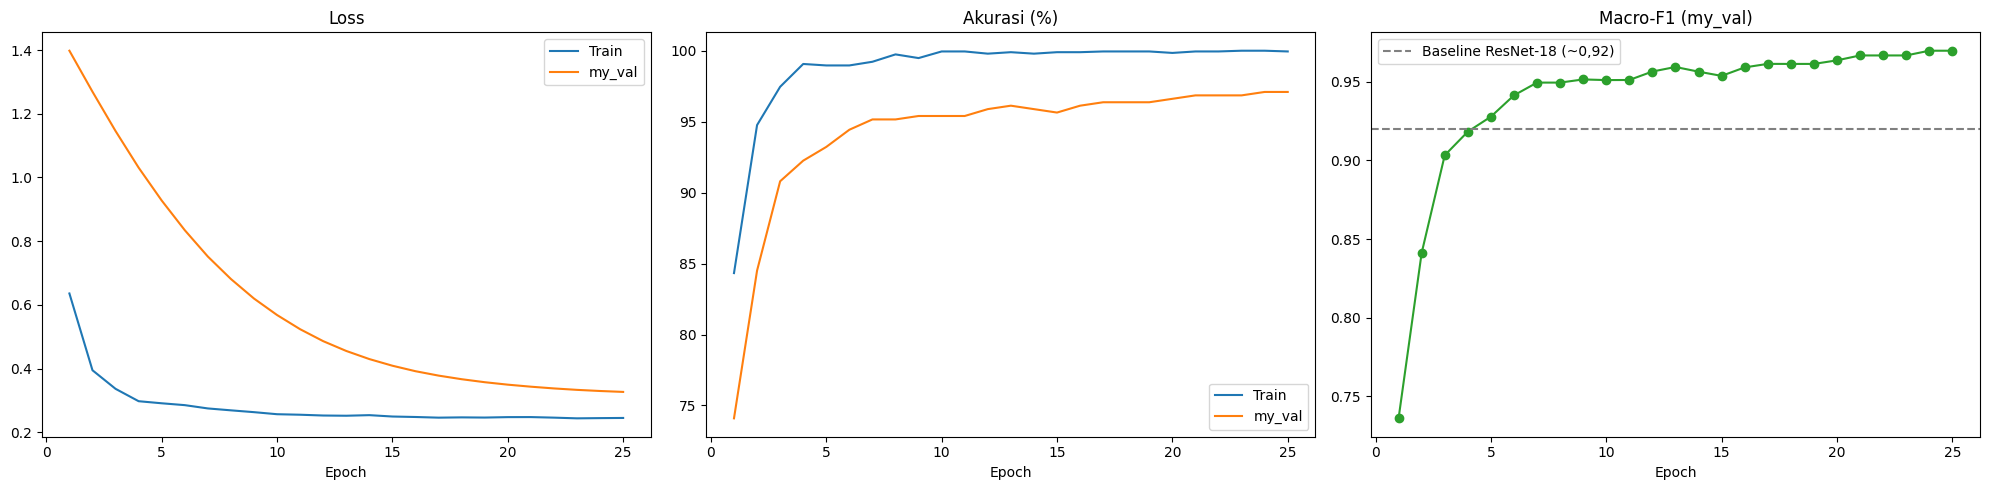

In [11]:
# Kurva loss, akurasi, dan Macro-F1 (jika pelatihan dijalankan pada sesi ini)
if len(history['train_loss']) > 0:
    ep = range(1, len(history['train_loss']) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    ax[0].plot(ep, history['train_loss'], label='Train'); ax[0].plot(ep, history['val_loss'], label='my_val')
    ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(ep, history['train_acc'], label='Train'); ax[1].plot(ep, history['val_acc'], label='my_val')
    ax[1].set_title('Akurasi (%)'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    ax[2].plot(ep, history['val_f1'], color='tab:green', marker='o')
    ax[2].axhline(0.92, color='gray', linestyle='--', label='Baseline ResNet-18 (~0,92)')
    ax[2].set_title('Macro-F1 (my_val)'); ax[2].set_xlabel('Epoch'); ax[2].legend()
    plt.tight_layout()
    plt.show()

### Ringkasan Arsitektur Model

In [12]:
try:
    from torchinfo import summary
except ImportError:
    !pip install torchinfo
    from torchinfo import summary

model_summary = summary(model, input_size=(batch_size, 3, sub_model.IMG_SIZE, sub_model.IMG_SIZE),
                        col_names=["input_size", "output_size", "num_params"],
                        col_width=20, row_settings=["var_names"], depth=2)

print(f"\nTotal Parameters: {model_summary.total_params:,}")
print(f"Estimasi ukuran bobot: {model_summary.total_params * 4 / (1024*1024):.2f} MB")


Total Parameters: 28,614,757
Estimasi ukuran bobot: 109.16 MB


## 8. Evaluasi pada `my_val`

Metrik utama: **Macro-F1**. Selain itu: confusion matrix, classification report (F1 per kelas), ROC/AUC, dan contoh prediksi.

Predicting: 100%|██████████| 13/13 [00:04<00:00,  3.09it/s]


Total sampel my_val : 413
Akurasi             : 97.09%
Macro-F1            : 0.9698   (baseline ResNet-18 ~0,92)


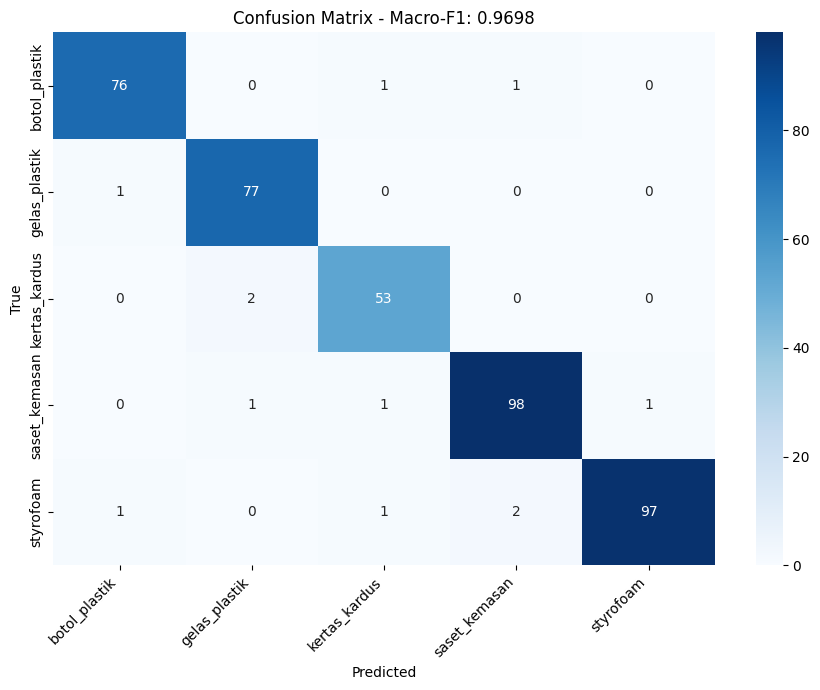


Classification Report (F1 per kelas):
               precision    recall  f1-score   support

botol_plastik     0.9744    0.9744    0.9744        78
gelas_plastik     0.9625    0.9872    0.9747        78
kertas_kardus     0.9464    0.9636    0.9550        55
saset_kemasan     0.9703    0.9703    0.9703       101
    styrofoam     0.9898    0.9604    0.9749       101

     accuracy                         0.9709       413
    macro avg     0.9687    0.9712    0.9698       413
 weighted avg     0.9712    0.9709    0.9710       413

Hasil detail disimpan ke 'detailed_val_results.csv'


In [13]:
val_preds, val_labels, val_probs, val_paths = predict(model, val_loader, device)

accuracy = (val_preds == val_labels).mean() * 100
macro_f1 = f1_score(val_labels, val_preds, average='macro')

print(f"{'='*50}")
print(f"Total sampel my_val : {len(val_labels)}")
print(f"Akurasi             : {accuracy:.2f}%")
print(f"Macro-F1            : {macro_f1:.4f}   (baseline ResNet-18 ~0,92)")
print(f"{'='*50}")

# Confusion matrix
cm = confusion_matrix(val_labels, val_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix - Macro-F1: {macro_f1:.4f}')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\nClassification Report (F1 per kelas):")
print(classification_report(val_labels, val_preds, target_names=class_names, digits=4))

pd.DataFrame({
    'path': val_paths,
    'predicted': [idx_to_label[p] for p in val_preds],
    'actual': [idx_to_label[l] for l in val_labels],
    'correct': val_preds == val_labels,
}).to_csv('detailed_val_results.csv', index=False)
print("Hasil detail disimpan ke 'detailed_val_results.csv'")

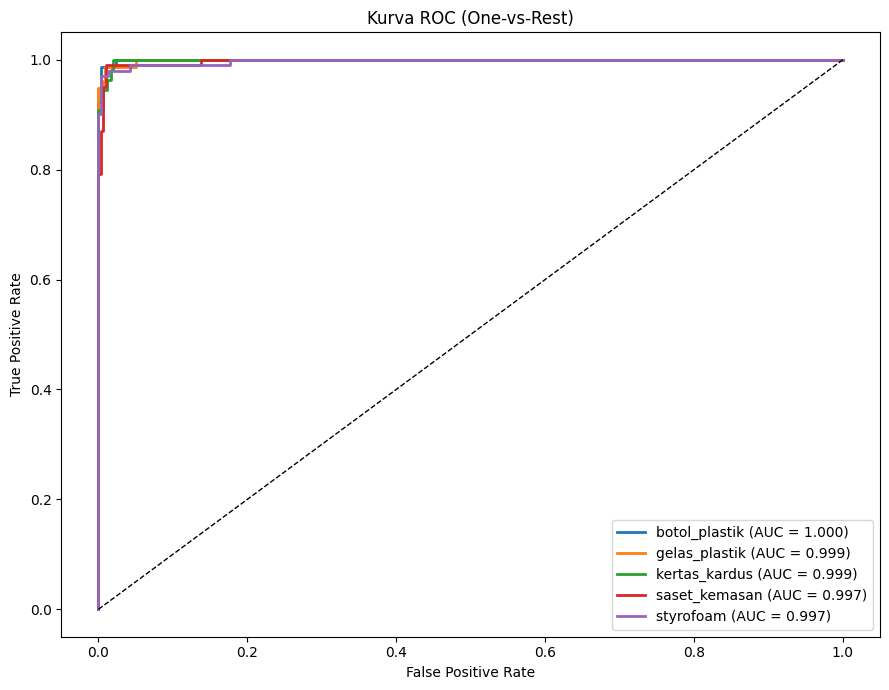

In [14]:
# Kurva ROC (one-vs-rest) dan AUC per kelas
y_bin = label_binarize(val_labels, classes=list(range(num_classes)))

plt.figure(figsize=(9, 7))
colors = cycle(['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple'])
for i, color in zip(range(num_classes), colors):
    fpr, tpr, _ = roc_curve(y_bin[:, i], val_probs[:, i])
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{class_names[i]} (AUC = {auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('Kurva ROC (One-vs-Rest)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

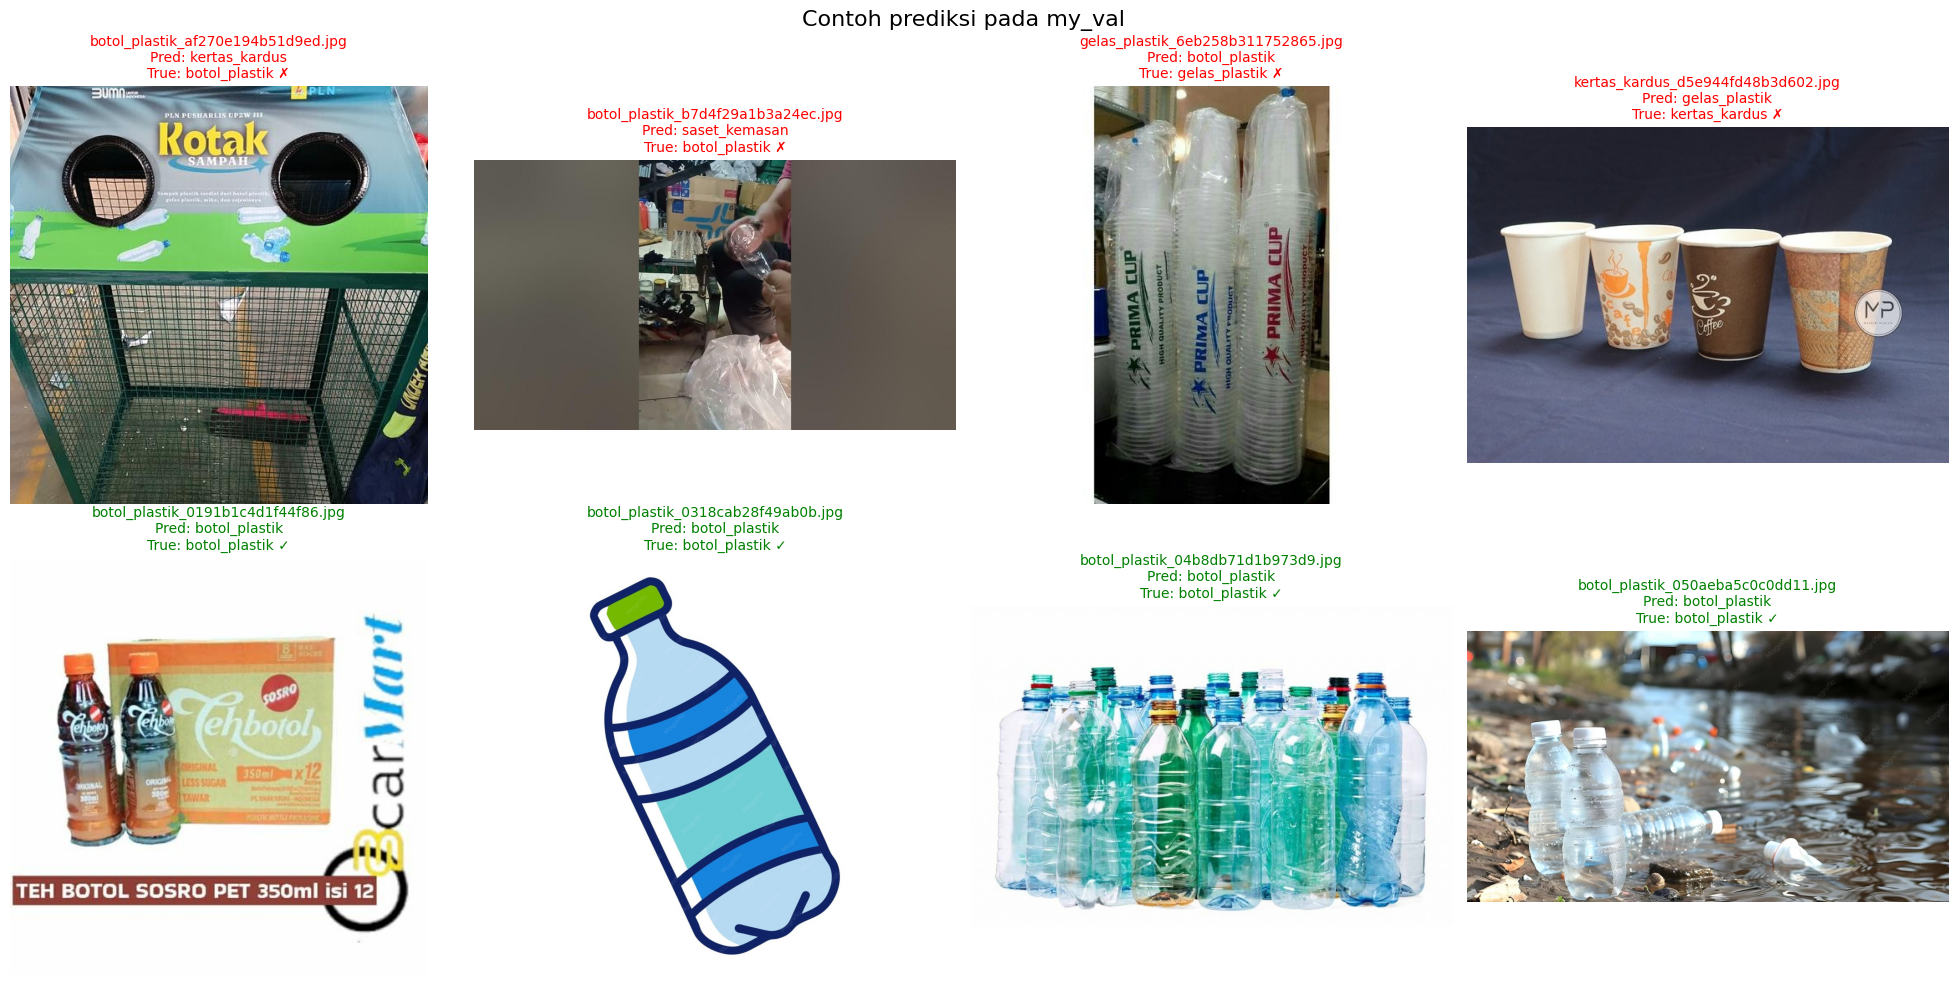

In [15]:
# Contoh prediksi (benar = hijau, salah = merah); salah diprioritaskan
wrong_idx = np.where(val_preds != val_labels)[0]
right_idx = np.where(val_preds == val_labels)[0]
show_idx = list(wrong_idx[:4]) + list(right_idx[:8 - min(4, len(wrong_idx))])

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()
for ax, i in zip(axes, show_idx):
    ax.imshow(Image.open(val_paths[i]).convert('RGB'))
    ok = val_preds[i] == val_labels[i]
    ax.set_title(f"{os.path.basename(val_paths[i])}\nPred: {idx_to_label[val_preds[i]]}\n"
                 f"True: {idx_to_label[val_labels[i]]} {'✓' if ok else '✗'}",
                 color='green' if ok else 'red', fontsize=10)
    ax.axis('off')
for ax in axes[len(show_idx):]:
    ax.axis('off')
plt.suptitle('Contoh prediksi pada my_val', fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

## 9. Evaluasi Akhir pada `my_test`

`test_loader` hanya digunakan setelah model terbaik dipilih berdasarkan hasil validasi. Hasil testing ini menjadi estimasi performa akhir pada data yang tidak dipakai untuk training maupun pemilihan model. Jangan gunakan hasil test untuk memilih hyperparameter atau checkpoint.

Predicting: 100%|██████████| 13/13 [00:04<00:00,  3.15it/s]


Total sampel test  : 413
Test accuracy      : 97.82%
Test Macro-F1      : 0.9780


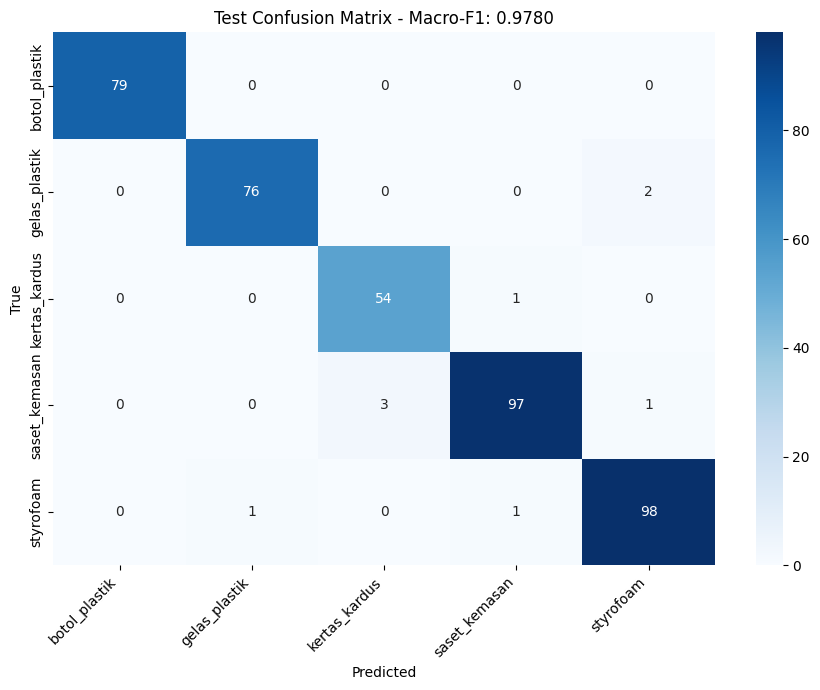


Test Classification Report (F1 per kelas):
               precision    recall  f1-score   support

botol_plastik     1.0000    1.0000    1.0000        79
gelas_plastik     0.9870    0.9744    0.9806        78
kertas_kardus     0.9474    0.9818    0.9643        55
saset_kemasan     0.9798    0.9604    0.9700       101
    styrofoam     0.9703    0.9800    0.9751       100

     accuracy                         0.9782       413
    macro avg     0.9769    0.9793    0.9780       413
 weighted avg     0.9784    0.9782    0.9782       413

Hasil detail test disimpan ke 'detailed_test_results.csv'


In [16]:
test_preds, test_labels, test_probs, test_paths = predict(
    model, test_loader, device
)

test_accuracy = (test_preds == test_labels).mean() * 100
test_macro_f1 = f1_score(test_labels, test_preds, average='macro')

print(f"{'='*50}")
print(f"Total sampel test  : {len(test_labels)}")
print(f"Test accuracy      : {test_accuracy:.2f}%")
print(f"Test Macro-F1      : {test_macro_f1:.4f}")
print(f"{'='*50}")

# Confusion matrix untuk data test
test_cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(
    test_cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names
)
plt.title(f'Test Confusion Matrix - Macro-F1: {test_macro_f1:.4f}')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\nTest Classification Report (F1 per kelas):")
print(classification_report(
    test_labels, test_preds, target_names=class_names, digits=4,
    zero_division=0
))

pd.DataFrame({
    'path': test_paths,
    'predicted': [idx_to_label[p] for p in test_preds],
    'actual': [idx_to_label[l] for l in test_labels],
    'correct': test_preds == test_labels,
}).to_csv('detailed_test_results.csv', index=False)
print("Hasil detail test disimpan ke 'detailed_test_results.csv'")

## 10. Verifikasi Submission (simulasi `evaluate.py`)

Sel ini meniru cara `evaluate.py` bekerja, memakai **hanya** isi folder `submission/`:
1. `get_model()` tanpa argumen (tanpa unduh bobot) lalu `load_state_dict` dari `model.pth`
2. `get_transform()` pada gambar PIL RGB dari `my_val/`
3. Macro-F1 harus sama dengan hasil evaluasi di atas
4. Cek batas teknis: ukuran `model.pth` ≤ 500 MB (>100 MB harus lewat GitHub Release / Git LFS), waktu evaluasi ≤ 15 menit

Jika file `evaluate.py` resmi dari starter kit ada di folder kerja, sel ini juga menjalankannya.

In [17]:
t0 = time.time()

check_model = sub_model.get_model()                        # tanpa pretrained / tanpa unduhan
state = torch.load('/kaggle/working/submission/model.pth', map_location='cpu')
assert isinstance(state, dict) and 'model_state_dict' not in state, \
    "model.pth harus state_dict murni, bukan dict checkpoint"
check_model.load_state_dict(state)                          # error jika kunci tidak cocok
check_model = check_model.to(device).eval()
tf = sub_model.get_transform()

preds, labels = [], []
batch_x, batch_y = [], []
def flush():
    global batch_x, batch_y
    if batch_x:
        with torch.no_grad():
            out = check_model(torch.stack(batch_x).to(device))
        preds.extend(out.argmax(1).cpu().numpy()); labels.extend(batch_y)
        batch_x, batch_y = [], []

for path, lbl in tqdm(val_samples, desc='Simulasi evaluate.py'):
    batch_x.append(tf(Image.open(path).convert('RGB'))); batch_y.append(lbl)
    if len(batch_x) == 64:
        flush()
flush()

check_f1 = f1_score(labels, preds, average='macro')
elapsed = time.time() - t0
size_mb = os.path.getsize('submission/model.pth') / (1024 * 1024)

print(f"Macro-F1 simulasi : {check_f1:.4f} (hasil evaluasi di atas: {macro_f1:.4f}, selisih {abs(check_f1 - macro_f1):.6f})")
print(f"Output model       : logits [batch, {check_model(torch.zeros(1,3,sub_model.IMG_SIZE,sub_model.IMG_SIZE).to(device)).shape[1]}]")
print(f"Ukuran model.pth   : {size_mb:.1f} MB  (batas 500 MB; >100 MB -> GitHub Release / Git LFS)")
print(f"Waktu evaluasi     : {elapsed:.1f} detik untuk {len(val_samples)} gambar (batas 15 menit untuk ~740 gambar)")

if os.path.exists('evaluate.py'):
    print("\nMenjalankan evaluate.py resmi...")
    res = subprocess.run([sys.executable, 'evaluate.py', '--submission', './submission', '--data', './my_val'],
                         capture_output=True, text=True)
    print(res.stdout); print(res.stderr)
else:
    print("\nevaluate.py belum ada di folder kerja. Salin dari starter kit lalu jalankan:")
    print("  python evaluate.py --submission ./submission --data ./my_val")

Simulasi evaluate.py: 100%|██████████| 413/413 [00:09<00:00, 43.88it/s]


Macro-F1 simulasi : 0.9698 (hasil evaluasi di atas: 0.9698, selisih 0.000000)
Output model       : logits [batch, 5]
Ukuran model.pth   : 109.2 MB  (batas 500 MB; >100 MB -> GitHub Release / Git LFS)
Waktu evaluasi     : 10.3 detik untuk 413 gambar (batas 15 menit untuk ~740 gambar)

evaluate.py belum ada di folder kerja. Salin dari starter kit lalu jalankan:
  python evaluate.py --submission ./submission --data ./my_val


## 11. Sebelum Commit

Dataset tidak boleh masuk repo publik. Sel di bawah menambahkan aturan ke `.gitignore` agar `my_val/`, `train/`, dan arsip dataset tidak ikut ter-commit.

Checklist repo (di luar notebook): `README.md` (nama kelompok, **nama lengkap + NIM semua anggota**, ringkasan pendekatan, sumber data tambahan jika ada, cara reproduksi), salinan `evaluate.py`, `submission/model.py`, dan `submission/model.pth` (jika >100 MB gunakan GitHub Release atau Git LFS dan tulis tautannya di README). Commit secara berkala.

In [18]:
from pathlib import Path

SUBMISSION_DIR = Path("/kaggle/working/submission")
MODEL_PATH = SUBMISSION_DIR / "model.pth"

assert MODEL_PATH.is_file(), f"Model not found: {MODEL_PATH}"

state = torch.load(MODEL_PATH, map_location="cpu")
print("Loaded object type:", type(state))
print("Number of state-dict keys:", len(state))
print("First 10 keys:", list(state.keys())[:10])

Loaded object type: <class 'dict'>
Number of state-dict keys: 189
First 10 keys: ['features.0.0.weight', 'features.0.0.bias', 'features.0.1.weight', 'features.0.1.bias', 'features.1.0.layer_scale', 'features.1.0.block.0.weight', 'features.1.0.block.0.bias', 'features.1.0.block.2.weight', 'features.1.0.block.2.bias', 'features.1.0.block.3.weight']


In [19]:
rules = ['my_val/', 'my_test/', 'train/', 'dataset_mahasiswa/', '*.zip', 'detailed_val_results.csv']
existing = open('.gitignore').read().splitlines() if os.path.exists('.gitignore') else []
to_add = [r for r in rules if r not in existing]
if to_add:
    with open('.gitignore', 'a') as f:
        f.write(('\n' if existing and existing[-1] != '' else '') + '\n'.join(to_add) + '\n')
print(".gitignore diperbarui:", to_add if to_add else "sudah lengkap")

.gitignore diperbarui: ['my_val/', 'my_test/', 'train/', 'dataset_mahasiswa/', '*.zip', 'detailed_val_results.csv']


In [20]:
# Daftar paket lingkungan pelatihan (untuk dokumentasi; submission/requirements.txt cukup torch, torchvision, pillow, numpy yang sudah tersedia)
!pip freeze > requirements_training.txt